# Simple CNN

### Imports

In [227]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import pandas as pd
import numpy as np
import torch.nn.functional as F
import random
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
import torch.optim as optim
from tqdm import tqdm
import os
import csv
from PIL import Image
import h5py

In [228]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

SEED = 173

random.seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

set_seed(SEED)

device = torch.device("cuda")

### Wczytanie danych

In [229]:
batch_size = 32

In [230]:
ONE_HOT_MAPPING = {
    np.bytes_(b'GALAXY'): 0,
    np.bytes_(b'QSO'): 1,
    np.bytes_(b'STAR'): 2
}

In [231]:
with h5py.File('../data/raw/image_table_galaxies.hdf5', 'r') as f:
   galaxies_data = f['ground'][:]
with h5py.File('../data/raw/image_table_qso.hdf5', 'r') as f:
   qso_data = f['ground'][:]
with h5py.File('../data/raw/image_table_stars.hdf5', 'r') as f:
   stars_data = f['ground'][:]

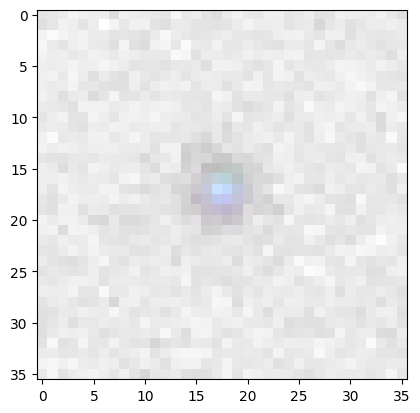

In [232]:
image = qso_data[0]['image']
image = (image - image.min()) / (image.max() - image.min())
plt.imshow(image)

In [233]:
train_data, test_data = train_test_split(np.concatenate((galaxies_data, qso_data, stars_data)), test_size=0.2, random_state=SEED)
validation_data, test_data = train_test_split(test_data, test_size=0.5, random_state=SEED)

In [234]:
class DSODataset(torch.utils.data.Dataset):
    def __init__(self, data, transform):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]
        image = sample['image']
        image = torch.tensor(image, dtype=torch.float32)
        image = image.transpose(0, 2)
        image = self.transform(image)
        label = sample['SPECTYPE']
        label = ONE_HOT_MAPPING[label]
        return image, label

In [235]:
transform = transforms.Compose([
    transforms.Lambda(lambda x: x)
])
trainset = DSODataset(train_data, transform=transform)

In [236]:
print(trainset[0][0].shape)

torch.Size([4, 36, 36])


In [237]:
sample = trainset[4]
print(f"PIL -> Tensor: shape={sample[0].shape} | dtype={sample[0].dtype} | min={sample[0].min()} | max={sample[0].max()}")

all_samples = torch.stack([sample[0] for sample in trainset])

channel_means = all_samples.mean(axis=(0,2,3))
channel_stds = all_samples.std(axis=(0,2,3))
print(f"Data norm per channel: mean={channel_means} | std={channel_stds}")


PIL -> Tensor: shape=torch.Size([4, 36, 36]) | dtype=torch.float32 | min=-2.2183926570717993e-11 | max=7.725987904994014e-11
Data norm per channel: mean=tensor([3.5303e-12, 1.0725e-11, 1.9955e-11, 2.7457e-11]) | std=tensor([2.5588e-11, 8.2183e-11, 1.4598e-10, 2.0976e-10])


In [238]:
transform = transforms.Compose(
    [transforms.Normalize((3.5303e-12, 1.0725e-11, 1.9955e-11, 2.7457e-11), (2.5588e-11, 8.2183e-11, 1.4598e-10, 2.0976e-10))])

trainset = DSODataset(train_data, transform=transform)
valset = DSODataset(validation_data, transform=transform)
testset = DSODataset(test_data, transform=transform)

In [239]:
augmentation_transform = transforms.Compose(
    [transforms.RandomHorizontalFlip(0.5),
     transforms.RandomRotation(15),
     transforms.RandomErasing(0.2),
     transforms.Normalize((3.5303e-12, 1.0725e-11, 1.9955e-11, 2.7457e-11), (2.5588e-11, 8.2183e-11, 1.4598e-10, 2.0976e-10))])

trainset.transform = augmentation_transform

In [240]:
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=16)
valloader = torch.utils.data.DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=16)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=16)

### Model

In [241]:
class MyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(4, 32, 3, 1, 1)
        self.batchnorm1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 32, 3, 1, 1)
        self.batchnorm2 = nn.BatchNorm2d(32)
        self.skip1 = nn.Sequential(
            nn.Conv2d(4, 32, kernel_size=1),
            nn.BatchNorm2d(32)
        )
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv3 = nn.Conv2d(32, 64, 3, 1, 1)
        self.batchnorm3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 64, 3, 1, 1)
        self.batchnorm4 = nn.BatchNorm2d(64)
        self.skip2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=1),
            nn.BatchNorm2d(64)
        )
        self.pool2 = nn.MaxPool2d(2, 2)

        self.conv5 = nn.Conv2d(64, 128, 3, 1, 1)
        self.batchnorm5 = nn.BatchNorm2d(128)
        self.conv6 = nn.Conv2d(128, 128, 3, 1, 1)
        self.batchnorm6 = nn.BatchNorm2d(128)
        self.skip3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=1),
            nn.BatchNorm2d(128)
        )
        self.pool3 = nn.MaxPool2d(2, 2)

        self.conv7 = nn.Conv2d(128, 256, 3, 1, 1)
        self.batchnorm7 = nn.BatchNorm2d(256)
        self.conv8 = nn.Conv2d(256, 256, 3, 1, 1)
        self.batchnorm8 = nn.BatchNorm2d(256)
        self.skip4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=1),
            nn.BatchNorm2d(256)
        )
        self.pool4 = nn.MaxPool2d(2, 2)

        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        self.fc1 = nn.Linear(256, 64)
        self.do1 = nn.Dropout(0.3)
        self.fc2 = nn.Linear(64, 50)

    def forward(self, x):
        identity = self.skip1(x)
        x = self.conv1(x)
        x = self.batchnorm1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = self.batchnorm2(x)
        x = F.relu(x + identity)
        x = self.pool1(x)

        identity = self.skip2(x)
        x = self.conv3(x)
        x = self.batchnorm3(x)
        x = F.relu(x)
        x = self.conv4(x)
        x = self.batchnorm4(x)
        x = F.relu(x + identity)
        x = self.pool2(x)

        identity = self.skip3(x)
        x = self.conv5(x)
        x = self.batchnorm5(x)
        x = F.relu(x)
        x = self.conv6(x)
        x = self.batchnorm6(x)
        x = F.relu(x + identity)
        x = self.pool3(x)

        identity = self.skip4(x)
        x = self.conv7(x)
        x = self.batchnorm7(x)
        x = F.relu(x)
        x = self.conv8(x)
        x = self.batchnorm8(x)
        x = F.relu(x + identity)
        x = self.pool4(x)

        x = self.gap(x)
        x = torch.flatten(x, start_dim=1)
        # print(x.size())

        x = F.relu(self.fc1(x))
        x = self.do1(x)
        x = self.fc2(x)

        return x

In [242]:
set_seed(173)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
model = MyNet().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

model

MyNet(
  (conv1): Conv2d(4, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchnorm1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchnorm2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (skip1): Sequential(
    (0): Conv2d(4, 32, kernel_size=(1, 1), stride=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchnorm3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchnorm4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (skip2): Sequential(
    (0): Conv2d(32,

In [243]:
num_params = sum(p.numel() for p in model.parameters())
print(f"Number of parameters: {num_params}")

Number of parameters: 1238738


In [244]:
EPOCHS = 200

In [245]:
train_log = []
val_log = []

for epoch in tqdm(range(EPOCHS)):

    running_loss = 0.0
    for data in trainloader:
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print('[%d/%d] Train loss: %.3f' %
          (epoch+1, EPOCHS, running_loss))
    train_log.append(running_loss)
    running_loss = 0.0

    with torch.no_grad():
        for data in valloader:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item()
    val_loss = running_loss * 8
    print('[%d/%d] Val loss: %.3f' %
          (epoch+1, EPOCHS, val_loss))
    val_log.append(val_loss)
    scheduler.step(val_loss)
    running_loss = 0.0

print('Finished Training')

  0%|          | 0/200 [00:00<?, ?it/s]

[1/200] Train loss: 596.074


  0%|          | 1/200 [00:04<13:36,  4.10s/it]

[1/200] Val loss: 501.193
[2/200] Train loss: 513.248


  1%|          | 2/200 [00:07<12:56,  3.92s/it]

...

[198/200] Val loss: 382.616
[199/200] Train loss: 346.412


100%|█████████▉| 199/200 [12:14<00:03,  3.71s/it]

[199/200] Val loss: 379.121
[200/200] Train loss: 344.201


100%|██████████| 200/200 [12:18<00:00,  3.69s/it]

[200/200] Val loss: 381.585
Finished Training


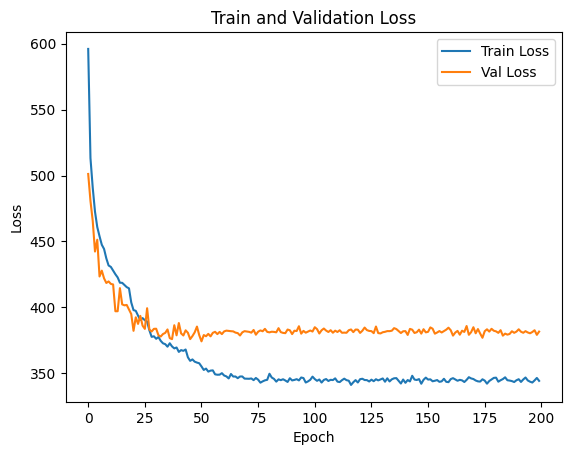

In [246]:
plt.plot(train_log, label='Train Loss')
plt.plot(val_log, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train and Validation Loss')
plt.legend()
plt.show()

In [247]:
classes = ["GALAXY", "QSO", "STAR"]

In [248]:
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        outputs = model(images).cpu()
        _, predictions = torch.max(outputs, 1)
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


accuracies = []

for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    accuracies.append(accuracy)
    print("Accuracy for class {:6s} is: {:.1f} %".format(classname,
                                                   accuracy))

print(f"Average accuracy: {np.mean(accuracies):.2f} %")

Accuracy for class GALAXY is: 96.9 %
Accuracy for class QSO    is: 92.7 %
Accuracy for class STAR   is: 96.8 %
Average accuracy: 95.47 %


In [249]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params}")

Total parameters: 1238738


In [250]:
torch.save(model.state_dict(), "../models/simple_cnn.pth")